In [39]:
import pandas as pd
import numpy as np
import tensorflow as tf
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

In [40]:
# Load the data
df = pd.read_csv('PT_LS_dataset.csv')
df.head()

,primary_type,secondary_type,LearningStyle_DimensionMentors_Active/ Reflective,LearningStyle_DimensionPioneers_Sequential/ Global,LearningStyle_DimensionConquerors_Sensing/ Intuitive,LearningStyle_Dimension4_Visual/ Verbal,Class Labels
0,Killer,Explorer,Reflective,Global,Sensing,Verbal,Mentors
1,Killer,Achiever,Active,Global,Sensing,Visual,Mentors
2,Socializer,Killer,Active,Sequential,Sensing,Verbal,Mentors
3,Achiever,Socializer,Reflective,Global,Sensing,Verbal,Visionaries
4,Explorer,Achiever,Active,Global,Sensing,Verbal,Mentors


In [41]:
# Split the features and target variable
X = df[['primary_type', 'secondary_type', 'LearningStyle_DimensionMentors_Active/ Reflective', 'LearningStyle_DimensionPioneers_Sequential/ Global', 'LearningStyle_DimensionConquerors_Sensing/ Intuitive', 'LearningStyle_Dimension4_Visual/ Verbal']]
y = df['Class Labels']

In [42]:
# One-hot encode the categorical columns
categorical_columns = ['primary_type', 'secondary_type', 'LearningStyle_DimensionMentors_Active/ Reflective', 'LearningStyle_DimensionPioneers_Sequential/ Global', 'LearningStyle_DimensionConquerors_Sensing/ Intuitive', 'LearningStyle_Dimension4_Visual/ Verbal']
# Remove the 'sparse' argument, or set handle_unknown='ignore' to avoid unseen values during prediction.
encoder = OneHotEncoder(handle_unknown='ignore') # sparse=False is deprecated

# Prepare the preprocessing pipeline: scale numerical features and one-hot encode categorical features
# Only apply StandardScaler to numerical features, and OneHotEncoder to categorical features.
preprocessor = ColumnTransformer(
    transformers=[
        # Removed StandardScaler from here as it's only for numerical features
        ('cat', encoder, categorical_columns)
    ])

In [43]:
# Apply preprocessing steps to data
X_processed = preprocessor.fit_transform(X)


In [44]:
# One-hot encode the target (Proposed Question Type)
y_encoded = pd.get_dummies(y)


In [49]:
print(X_processed)


[[0. 0. 1. ... 1. 1. 0.]
 [0. 0. 1. ... 1. 0. 1.]
 [0. 0. 0. ... 1. 1. 0.]
 ...
 [0. 1. 0. ... 1. 1. 0.]
 [1. 0. 0. ... 1. 0. 1.]
 [0. 1. 0. ... 0. 0. 1.]]


In [50]:
print(y_encoded)

      Conquerors  Mentors  Pioneers  Visionaries
0          False     True     False        False
1          False     True     False        False
2          False     True     False        False
3          False    False     False         True
4          False     True     False        False
...          ...      ...       ...          ...
1035       False    False      True        False
1036       False    False      True        False
1037       False    False      True        False
1038        True    False     False        False
1039       False    False     False         True

[1040 rows x 4 columns]


In [23]:
# Split the data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X_processed, y_encoded, test_size=0.2, random_state=42)


In [24]:
# Build the model
model = tf.keras.Sequential([
    tf.keras.layers.InputLayer(input_shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(y_encoded.shape[1], activation='softmax')
])


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(


In [25]:
# Compile the model
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,300 (12.89 KB)

 Trainable params: 3,300 (12.89 KB)

 Non-trainable params: 0 (0.00 B)

In [26]:
# Train the model
history = model.fit(X_train, y_train, epochs=500, batch_size=8, validation_data=(X_test, y_test))


Epoch 1/500
104/104 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.5670 - loss: 1.0741 - val_accuracy: 0.8558 - val_loss: 0.5108
Epoch 2/500
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8813 - loss: 0.3968 - val_accuracy: 0.9327 - val_loss: 0.2488
Epoch 3/500
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9442 - loss: 0.2108 - val_accuracy: 0.9904 - val_loss: 0.1575
Epoch 4/500
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9755 - loss: 0.1645 - val_accuracy: 0.9904 - val_loss: 0.1094
Epoch 5/500
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9927 - loss: 0.1013 - val_accuracy: 1.0000 - val_loss: 0.0777
Epoch 6/500
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9997 - loss: 0.0673 - val_accuracy: 1.0000 - val_loss: 0.0497
Epoch 7/500
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 1.0000 - loss: 0.0535 - val_accuracy: 1.0000 - val_loss: 0.0414
Epoch 8/500
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 1.0000 - loss: 0.0433 - val_accu

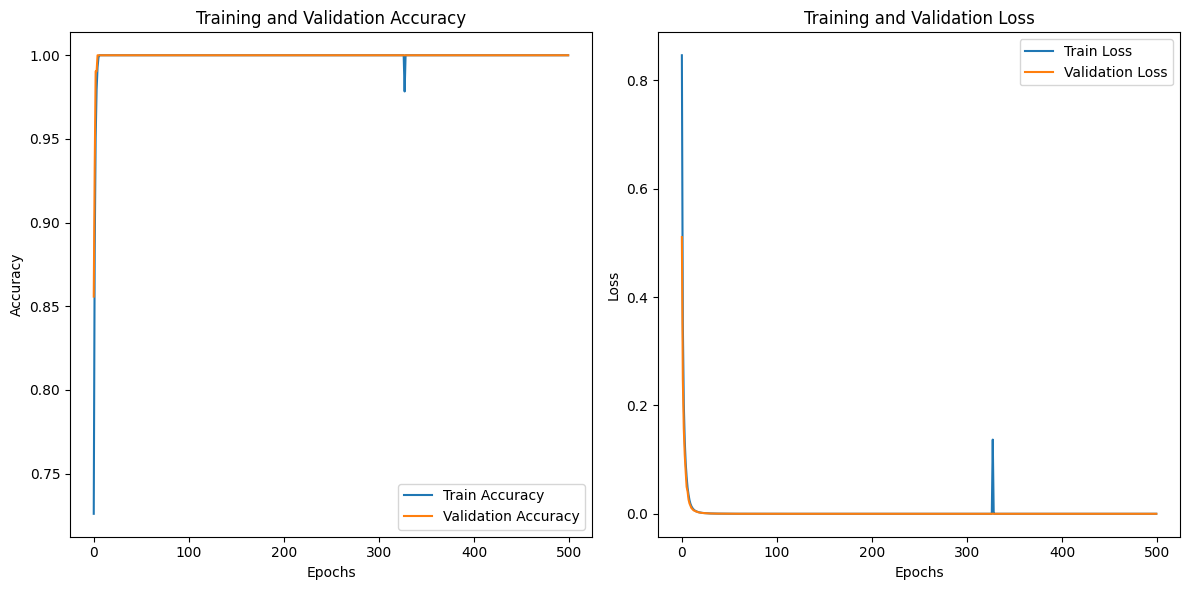

In [27]:
# Plot training and validation accuracy
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Plot training and validation loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step


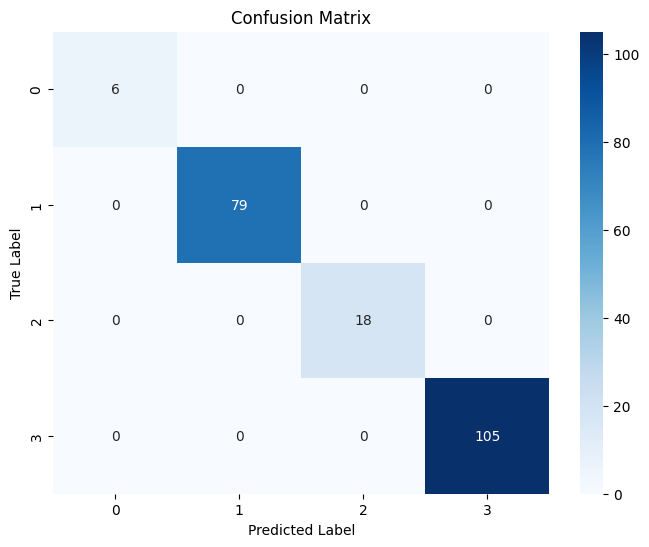

In [28]:
# Make predictions on the test data
y_pred = model.predict(X_test)

# Convert the one-hot encoded predictions and true labels into class indices
y_pred_classes = np.argmax(y_pred, axis=1)  # Predicted class indices
y_true_classes = np.argmax(y_test, axis=1)  # True class indices

# Generate the confusion matrix
conf_matrix = confusion_matrix(y_true_classes, y_pred_classes)

# Plot the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

In [29]:
# Generate the classification report
report = classification_report(y_true_classes, y_pred_classes)

# Print the classification report
print(report)


              precision    recall  f1-score   support

           0       1.00      1.00      1.00         6
           1       1.00      1.00      1.00        79
           2       1.00      1.00      1.00        18
           3       1.00      1.00      1.00       105

    accuracy                           1.00       208
   macro avg       1.00      1.00      1.00       208
weighted avg       1.00      1.00      1.00       208



In [31]:
# Save the model and preprocessor
model.save('PT_LS_Model.h5')
joblib.dump(preprocessor, 'preprocessor_PT_LS.pkl')


['preprocessor_PT_LS.pkl']

In [51]:
from sklearn.preprocessing import LabelEncoder

# Original categories
categories = ["Mentors", "Visionaires", "Conquerors", "Pioneers"]

# Initialize and fit the encoder
le = LabelEncoder()
le.fit(categories)

# View the mapping
for index, label in enumerate(le.classes_):
    print(f"{label} => {index}")


Conquerors => 0
Mentors => 1
Pioneers => 2
Visionaires => 3
